# Analysis Report Assignment: Colors
### Coco Renfroe
### Nov. 15, 2026

>>

>The dataset I chose to analyze is the Colors dataset from https://jsonlint.com/datasets/colors. I chose this dataset because I felt the RGB values would be interesting to explore in an analysis and they have numerical values as well as written categories.

>The dataset includes a name, hex code, and the colors broken down by the value of red, blue and green (RGB). It also includes the category it's listed in with options of primary, secondary, neutral, warm, cool, earth, and nature as the categories. Additionally, the dataset has more tha 20 observations, which fits the instructions of the assignment

### *VARIABLES*
The variables I plan to investigate are the RGB values and the color categories in relation to one another.

### *Hypothesis/Research Question*

I believe that all of the colors in this dataset which are labeled as "warm" will have more than 33% (1/3) of their RGB values in the "red" category. RGB has a range from 0 to 255. 33% is about 170 on the scale of 0 to 255. Red is colloquially considered a "warm" color, and color theory as a discipline backs up this anecdotal evidence.

In [185]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_json("colors.json")

with open('colors.json', 'r') as f:
    data = json.load(f)


Imported pandas and matplotlib.pyplot as shown in class on 11_2, loaded in the JSON file.

In [186]:

tidy_rows = []

for entry in data['colors']:
    row = {}
    row['name'] = entry['name']
    row['hex'] = entry['hex']
    row['category'] = entry['category']
    row['r'] = entry['rgb']['r']
    row['g'] = entry['rgb']['g']
    row['b'] = entry['rgb']['b']
    tidy_rows.append(row)

df = pd.DataFrame(tidy_rows)
df.head()


df['total'] = df['r'] + df['g'] + df['b']
df = df[df['total'] > 0].copy()          # drops Black (total = 0, so its share would be undefined)
df['red_share'] = df['r'] / df['total']
df.head()

,name,hex,category,r,g,b,total,red_share
1,White,#FFFFFF,neutral,255,255,255,765,0.333333
2,Red,#FF0000,primary,255,0,0,255,1.000000
3,Green,#00FF00,primary,0,255,0,255,0.000000
4,Blue,#0000FF,primary,0,0,255,255,0.000000
5,Yellow,#FFFF00,secondary,255,255,0,510,0.500000


I used Claude in the above code box to correct my syntax for un-nesting the data as the "normalize" code we did in class was throwing errors for me and I couldn't get it to work properly.

In [187]:
warm = df[df['category'] == 'warm']
rgb_totals = warm[['r', 'g', 'b']].sum()

warm[['name', 'r', 'g', 'b', 'red_share']].sort_values('red_share')

,name,r,g,b,red_share
9,Pink,255,192,203,0.392308
33,Peach,255,203,164,0.409968
22,Salmon,250,128,114,0.508130
25,Gold,255,215,0,0.542553
21,Coral,255,127,80,0.551948
8,Orange,255,165,0,0.607143
26,Crimson,220,20,60,0.733333


The above data shows the name, rgb value, and red share (percentage of red) of each color in the "warm" category

The following code was a combination of my understanding of Python, Dr. Baumgartner's examples (this is how I knew to customize the title, etc and my understanding of bins), and was cleaned up by Claude. I changed the numbers of warm colors to whole numbers, because it doesn't make sense for discrete data to be visualized in a continuous way (I took a statistics class in my core college classes, so I understand statistics somewhat)

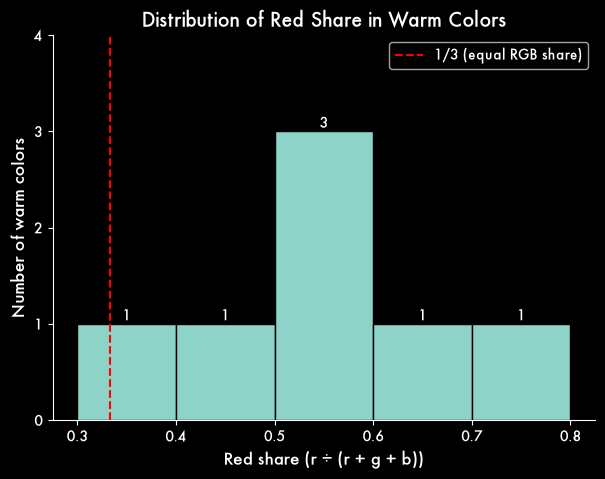

In [188]:
warm = df[df['category'] == 'warm']

counts, edges, patches = plt.hist(
    warm['red_share'],
    bins=[0.3, 0.4, 0.5, 0.6, 0.7, 0.8],
    edgecolor='black'
)

plt.bar_label(patches)                        
plt.yticks(range(0, int(counts.max()) + 2))     
plt.axvline(1/3, color='red', linestyle='--', label='1/3 (equal RGB share)')

plt.xlabel('Red share (r ÷ (r + g + b))')
plt.ylabel('Number of warm colors')
plt.title('Distribution of Red Share in Warm Colors')
plt.legend()
plt.show()

I attempted to make the bins 3, 5, and 10, but because the values are a percentage, the bins couldn't be any greater than 1.0, since percentages run from 0.00 to 1.00 as decimal points, from 0% to 100% respectively.

I found this distribution of data interesting, as someone who has taken statistics class, because although the sample size is small, the data seems to fall on a normal curve. It doesn't have a skew to it at all.

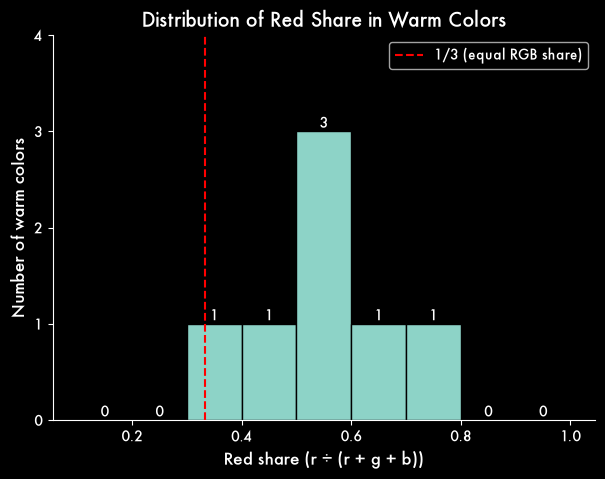

In [189]:
warm = df[df['category'] == 'warm']

counts, edges, patches = plt.hist(
    warm['red_share'],
    bins=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8 ,0.9, 1],
    edgecolor='black'
)

plt.bar_label(patches)                        
plt.yticks(range(0, int(counts.max()) + 2))     
plt.axvline(1/3, color='red', linestyle='--', label='1/3 (equal RGB share)')

plt.xlabel('Red share (r ÷ (r + g + b))')
plt.ylabel('Number of warm colors')
plt.title('Distribution of Red Share in Warm Colors')
plt.legend()
plt.show()

I tested out making the equivalent of ten bins by changing the bins to tenths instead of by ten. The data is visualized mostly the same, but it is zoomed out.

Because there's only seven colors in the warm category, to show the correlation, I the red share of the warm colors and the blue share of the warm colors. 


At this point, I realized my hypothesis was lacking because it doesn't take the blue or green values into account. For the scatterplot, I needed to compare at least one of the other numerical values, so I decided to create the scatterplot to compare red and blue values in warm colors. Red and green are opposite to one another on the color wheel, meaning they're likely direct opposites in the RGB color system, so I thought that red and blue were better to explore since their color relationship is more unknown to me.

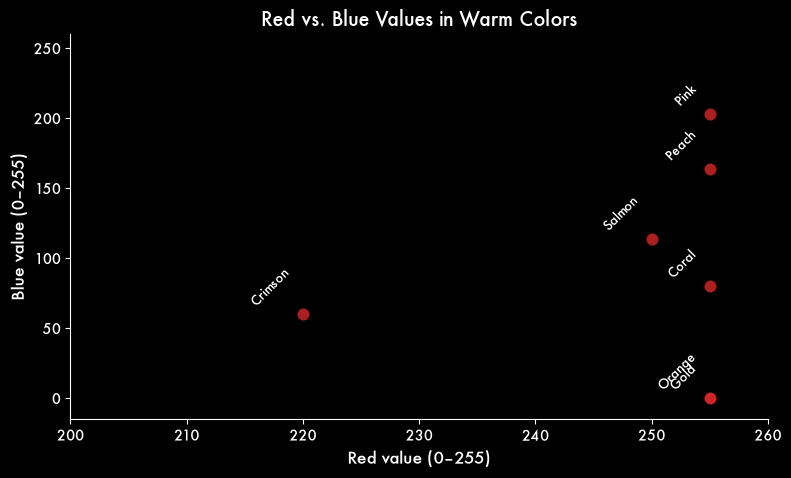

In [190]:
warm = df[df['category'] == 'warm']

plt.figure(figsize=(9, 5))

plt.scatter(warm['r'], warm['b'], color='#d62828', s=90, edgecolor='black', alpha=0.8)
for _, row in warm.iterrows():
    plt.annotate(row['name'], (row['r'], row['b']),
                 textcoords='offset points', xytext=(-8, 6),
                 ha='right', fontsize=9, rotation=45)


plt.xlim(200, 260)
plt.ylim(-15, 260)

plt.xlabel('Red value (0–255)')
plt.ylabel('Blue value (0–255)')
plt.title('Red vs. Blue Values in Warm Colors')
plt.show()

The correlation of red value vs blue is interesting. It supports my hypothesis that the colors labeled "warm" have a red value of over 33% (or 170 on the scale of 0 to 255). However, I would've expected the blue values to go down more dramatically as the red values went up, which would've grouped most of the points of the scatterplot in the bottom right corner of the plot.

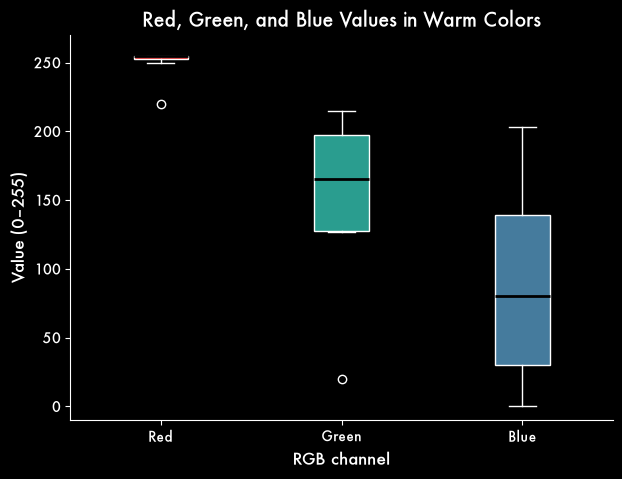

In [191]:
warm = df[df['category'] == 'warm']

plt.figure(figsize=(7, 5))

bp = plt.boxplot([warm['r'], warm['g'], warm['b']], patch_artist=True)

for box, color in zip(bp['boxes'], ['#d62828', '#2a9d8f', '#457b9d']):
    box.set_facecolor(color)   

for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(2)

plt.xticks([1, 2, 3], ['Red', 'Green', 'Blue'])
plt.ylim(-10, 270)

plt.xlabel('RGB channel')
plt.ylabel('Value (0–255)')
plt.title('Red, Green, and Blue Values in Warm Colors')
plt.show()

I decided to put all of the RGB catgories in the boxplot to compare their relationship. The red boxplot is not an error, but rather because most of the warm colors (besides the outlier, which is represented by the circle) are near the top of the 0-255 range, the box is very squished.

The boxplots are helpful because their mean, median, and mode are clearly marked, and it's easy to visualize how the data correlates to each other since the outliers are marked separately and aren't skewing the data. You can see that though red and green are opposite on the color wheel, they're more likely to have less of a difference in their values in a warm color compared to red and blue. 

## Begin Design Styling

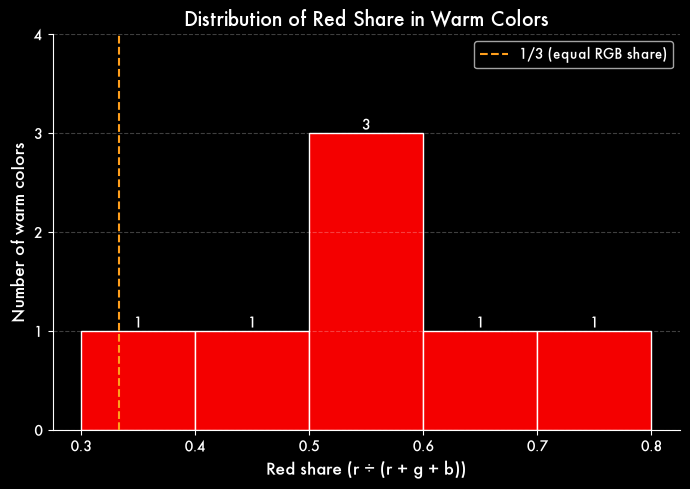

In [192]:
warm = df[df['category'] == 'warm']

fig, ax = plt.subplots()
counts, edges, patches = ax.hist(
    warm['red_share'], bins=[0.3, 0.4, 0.5, 0.6, 0.7, 0.8],
    color='#F40000', edgecolor='white'
)
ax.bar_label(patches, color='white')
ax.set_yticks(range(0, int(counts.max()) + 2))
ax.axvline(1/3, color='#FF9F1C', linestyle='--', label='1/3 (equal RGB share)')
ax.grid(axis='y')

ax.set_xlabel('Red share (r ÷ (r + g + b))')
ax.set_ylabel('Number of warm colors')
ax.set_title('Distribution of Red Share in Warm Colors')
ax.legend()
plt.rcParams['font.family'] = 'Futura'
plt.rcParams['font.size'] = 10
fig.tight_layout()
plt.show()

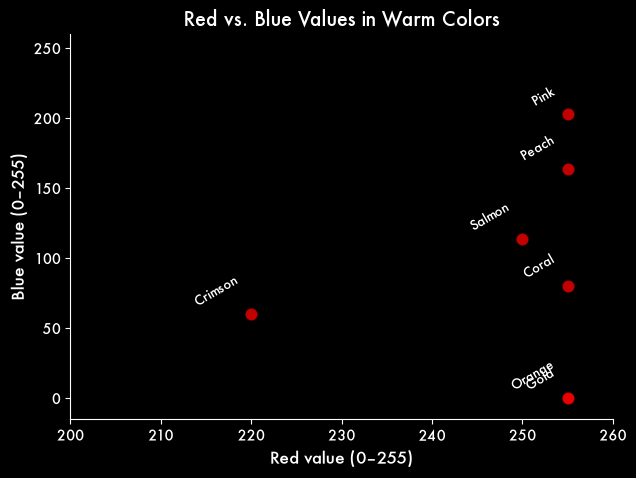

In [193]:
warm = df[df['category'] == 'warm']

plt.figure(figsize=(7, 5))

plt.scatter(warm['r'], warm['b'], color='#F40000', s=90, edgecolor='black', alpha=0.8)
for _, row in warm.iterrows():
    plt.annotate(row['name'], (row['r'], row['b']),
                 textcoords='offset points', xytext=(-8, 6),
                 ha='right', fontsize=9, rotation=30)


plt.xlim(200, 260)
plt.ylim(-15, 260)

plt.xlabel('Red value (0–255)')
plt.ylabel('Blue value (0–255)')
plt.title('Red vs. Blue Values in Warm Colors')
plt.show()

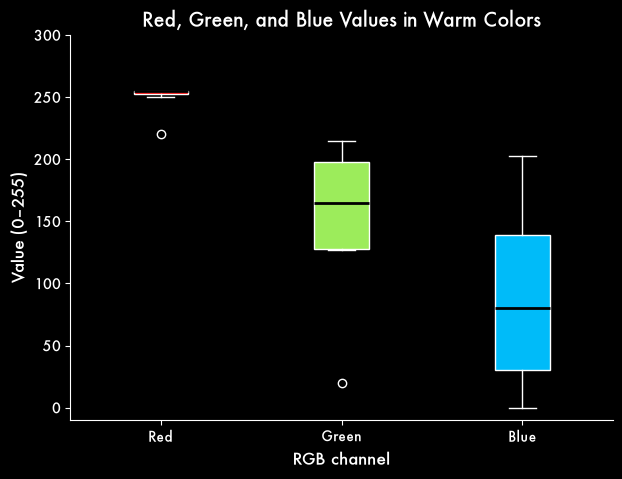

In [194]:
warm = df[df['category'] == 'warm']

plt.figure(figsize=(7, 5))

bp = plt.boxplot([warm['r'], warm['g'], warm['b']], patch_artist=True)

for box, color in zip(bp['boxes'], ['#F40000', '#9CEC5B', '#00BBF9']):
    box.set_facecolor(color)   

for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(2)

plt.xticks([1, 2, 3], ['Red', 'Green', 'Blue'])
plt.ylim(-10, 300)

plt.xlabel('RGB channel')
plt.ylabel('Value (0–255)')
plt.title('Red, Green, and Blue Values in Warm Colors')
plt.rcParams['font.family'] = 'Futura'
plt.rcParams['font.size'] = 10
plt.show()

I updated the code to make the background of the graphs and plots black and went in and changed the colors of the red, green, and blue box plots manually because I wanted the design to be a black background and neon colors. One of the code snippets I got from https://matplotlib.org/stable/gallery/style_sheets/dark_background.html changed all of my backgrounds to black and the lines and font of all the code, even the ones that I hadn't styled before the "begin styling" section. I didn't actually go in and change the styling until the "Begin Styling" section I delineated.

### Why I made the design changes I did

I chose to make the background black and make the colors more neon because I wanted the data to stand out. The default styling is very static and the colors are muted, so the data can be difficult to parse. Many people use dark mode on their devices. Also, the contrast of the bright colors and white against the black help with accessibility for those with visual impairment. I changed the font family to Futura because it is a sans-serif font which is easy to read at many different font sizes and provides a clean, modern look for the plots and graphs.

## Analysis

### *I chose to analyze my data using Option A*

I altered the code from class to work with my dataset and ran the regression. Because I have some understanding of statistics and P values, I felt that this method made the most sense for my data and for analyzing my hypothesis.

In [197]:
import statsmodels.formula.api as smf

groups = df[df['category'].isin(['warm', 'cool'])].copy()
groups['is_warm'] = (groups['category'] == 'warm').astype(int)

model = smf.ols('red_share ~ is_warm', data=groups).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:              red_share   R-squared:                       0.421
Model:                            OLS   Adj. R-squared:                  0.373
Method:                 Least Squares   F-statistic:                     8.736
Date:                Sun, 15 Nov 2026   Prob (F-statistic):             0.0120
Time:                        16:52:00   Log-Likelihood:                 6.6638
No. Observations:                  14   AIC:                            -9.328
Df Residuals:                      12   BIC:                            -8.050
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.2785      0.061      4.538      0.0

### In looking at the p value and knowing that the regular cutoff for significance is 0.05, a P value of 0.012 means that the red share of colors categorized as "warm" is statistically significant.

THe coefficient of is_warm = 0.2565 means warm colors average 0.2565 higher in red share than cool colors. This also supports my hypothesis, though my original hypothesis was based solely on the red value of colors categorized as warm

# Conclusion and Reflection

### Visualizations

The visualization most effective in communicating my results was the scatterplot. It shows the correlation of red value vs. blue value in an easy to understand way. The groupings of all of the "warm" colors towards the edge of the 0-255 range supports my hypothesis in a tangible way.

Though I could extrapolate that my hypothesis was correct from the percentages my dataset visualizations showed, the analysis of the p-value and coefficient give more concrete data using a tried and true scientific analysis. My p value is above 0.05, which means my hypothesis is not null. 


### Limitations

The biggest limitation for my hypothesis is the sample size. Results can be skewed astronomically by a single outlier, whereas if my sample size were out of hundreds of colors with at least 50 or more being warm colors, the data could be trusted more. 

Though my analysis captures the numerical values of color within RGB, the dataset category of "warm" may be done arbitrarily. The creator of the dataset may have used a personal categorical system to choose those colors as warm, and there's not a universal understanding of "warm" vs. "cool" colors. Personal bias in the dataset is not captured in my analysis. 

### How the data or approaches could be better
A concrete, universal grouping of colors by category from a much larger set of data would improve my investigation. It also might be helpful to analyze several datasets to eliminate possible biases. 

### Reflection

The gathering of data, visualization and analysis of my dataset was a very good exercise in how to implement Python and Jupyter Notebook in testing hypotheses. However, because the entire dataset is limited to about 30 observations, my data may be skewed. The use of statistics to calculate the P-value supports my hypothesis as being statisically significant, which means that further analysis and expansion of my research would be worth pursuing.